# Task 2: Exploratory Data Analysis of CIC-IDS2017

## Project Overview

This project performs Exploratory Data Analysis (EDA) on the cleaned Tuesday Working Hours subset of the CIC-IDS2017 network intrusion detection dataset.

## Objectives

- Understand the distribution and characteristics of network traffic.
- Analyze benign and attack traffic patterns.
- Calculate descriptive statistics for important network features.
- Visualize feature distributions and relationships.
- Identify at least five insights that could influence machine-learning models or security decisions.

## Tools Used

Python, Pandas, NumPy, Matplotlib, Seaborn, and Google Colab.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Saving CIC_IDS2017_Tuesday_Cleaned.csv to CIC_IDS2017_Tuesday_Cleaned.csv
Dataset loaded successfully!
Dataset shape: (421626, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,88,640,7,4,440,358,220,0,62.857143,107.349008,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,88,900,9,4,600,2944,300,0,66.666667,132.287566,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,88,1205,7,4,2776,2830,1388,0,396.571429,677.274651,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,88,511,7,4,452,370,226,0,64.571429,110.276708,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,88,773,9,4,612,2944,306,0,68.000000,134.933317,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [11]:
print("Dataset Shape:", df.shape)
print("\nTraffic Class Counts:")
print(df["Label"].value_counts())

print("\nTraffic Class Percentages:")
print((df["Label"].value_counts(normalize=True) * 100).round(2))

features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s"
]

display(df[features].describe().T)

Dataset Shape: (421626, 79)

Traffic Class Counts:
Label
BENIGN         412476
FTP-Patator      5931
SSH-Patator      3219
Name: count, dtype: int64

Traffic Class Percentages:
Label
BENIGN         97.83
FTP-Patator     1.41
SSH-Patator     0.76
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Flow Duration,421626.0,1.139456e+07,3.027584e+07,-4.0,208.000000,38665.500000,904894.000000,1.200000e+08
Total Fwd Packets,421626.0,1.235701e+01,8.916886e+02,1.0,1.000000,2.000000,4.000000,2.064460e+05
Total Backward Packets,421626.0,1.465610e+01,1.205439e+03,0.0,1.000000,2.000000,3.000000,2.760720e+05
Total Length of Fwd Packets,421626.0,5.573974e+02,5.836682e+03,0.0,31.000000,70.000000,171.000000,2.428415e+06
Flow Bytes/s,421626.0,1.300640e+06,2.352390e+07,0.0,4.816841,2452.123061,18274.342723,2.070000e+09
Flow Packets/s,421626.0,5.084145e+04,2.149420e+05,-2000000.0,9.494729,85.935570,17857.142860,3.000000e+06


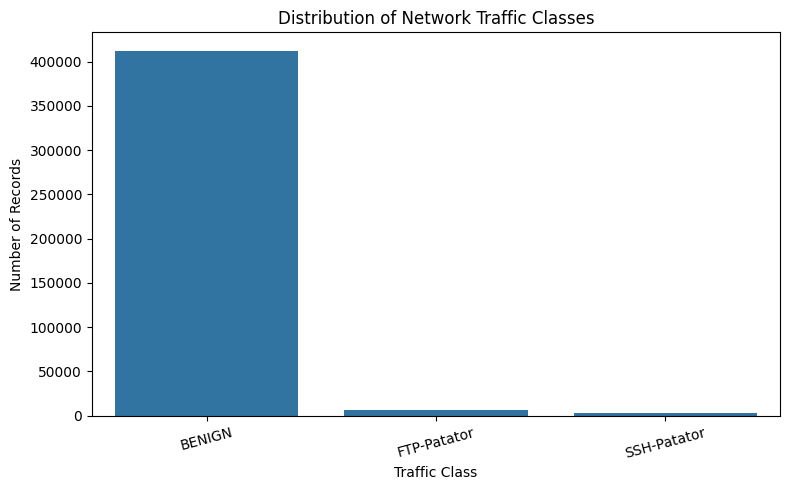

In [12]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Label")

plt.title("Distribution of Network Traffic Classes")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

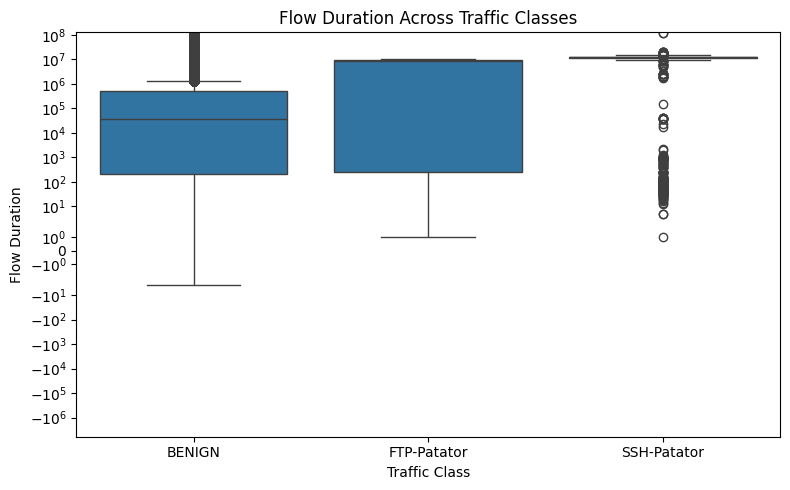

In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Label", y="Flow Duration")

plt.yscale("symlog")
plt.title("Flow Duration Across Traffic Classes")
plt.xlabel("Traffic Class")
plt.ylabel("Flow Duration")
plt.tight_layout()
plt.show()

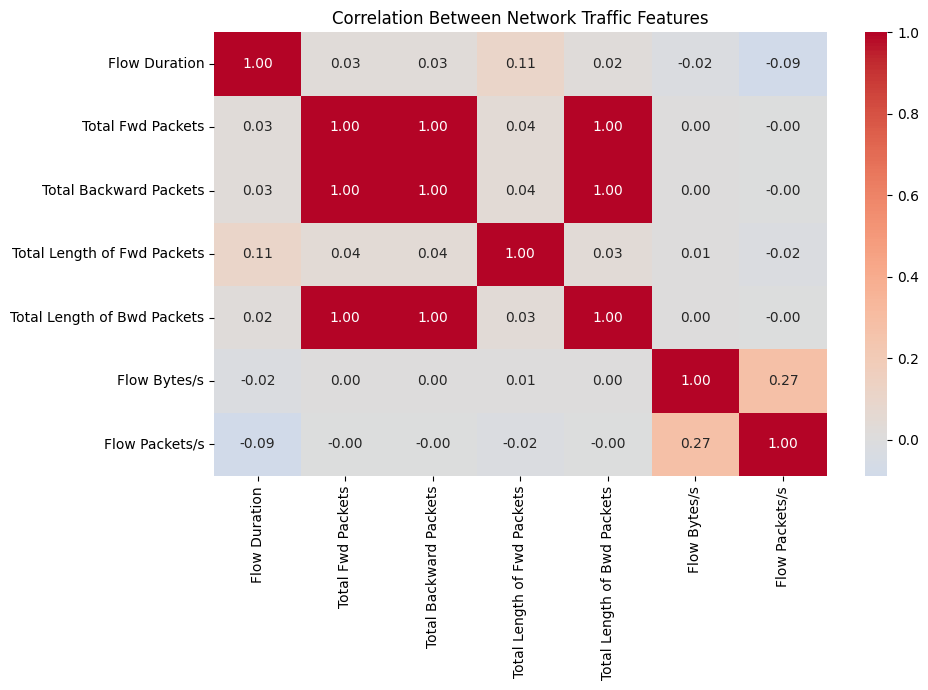

In [14]:
corr_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s"
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[corr_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Network Traffic Features")
plt.tight_layout()
plt.show()

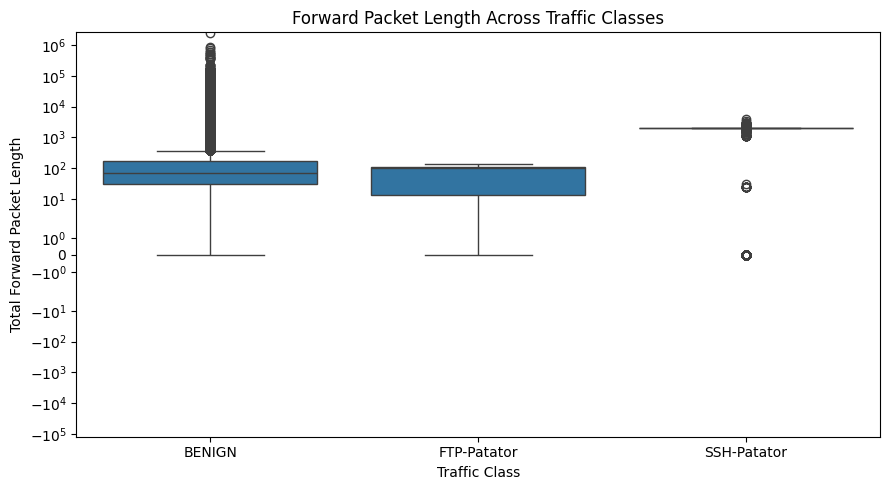

In [8]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Label",
    y="Total Length of Fwd Packets"
)

plt.title("Forward Packet Length Across Traffic Classes")
plt.xlabel("Traffic Class")
plt.ylabel("Total Forward Packet Length")
plt.yscale("symlog")
plt.tight_layout()
plt.show()

## Key Findings and Insights

### 1. Significant Class Imbalance
The dataset contains substantially more BENIGN traffic than FTP-Patator and SSH-Patator traffic. This imbalance could cause a machine-learning model to favor the majority class. Evaluation should include precision, recall, F1-score, and a confusion matrix rather than accuracy alone.

### 2. Different Traffic Class Distributions
The class distribution shows that benign and attack records are not equally represented. This should be considered when selecting training strategies and evaluating attack detection performance.

### 3. Variation in Flow Duration
Flow duration varies across network records. Comparing duration distributions between traffic classes can help determine whether this feature provides useful information for distinguishing traffic types.

### 4. Extreme Values in Packet-Length Features
The forward packet-length visualization shows extreme values, particularly within the BENIGN class. These observations should be investigated because extreme values can influence scaling, statistical summaries, and some machine-learning models.

### 5. Relationships Between Numerical Features
The correlation heatmap helps identify numerical features that move together. Highly correlated features may contain overlapping information, which can influence feature selection and model interpretation.

### Conclusion
The EDA highlights class imbalance, variation in network traffic characteristics, extreme values, and relationships between numerical features. These findings will guide feature selection, model evaluation, and subsequent network intrusion detection experiments.